# Tres maneras de dividir los mismos 97 tiros: aleatoria, sin duplicados y con campañas completas fuera

**Nivel 1: Fundamentos** · Requiere: 01-the-data/01-the-corpus-and-the-cases · Tiempo de lectura: unos 20 minutos

## Objetivos

Una predicción vale lo que puntúa en tiros que el modelo no ha visto, y qué tiros cuentan como no vistos depende de cómo se dividan los datos. Este cuaderno construye las tres divisiones que usa el producto sobre los mismos 97 tiros y mide qué deja pasar cada una.

Al terminar habrá:

- sorteado una división aleatoria 80/20, el protocolo que informa la literatura, y contado los tiros de prueba que comparten sus entradas con un tiro de entrenamiento;
- encontrado los vectores de entrada duplicados del corpus y sorteado una división que los colapsa primero;
- construido las diez divisiones de un sitio fuera y visto cómo la verificación de fuga rechaza una división que pone una campaña a ambos lados.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los grupos de duplicados y los conteos por sitio versionados | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json`, campos `duplicate_groups` y `site_counts` |

El protocolo aleatorio 80/20 es el que informan los estudios de predictores aprendidos (Sui et al. 2025, https://doi.org/10.3390/app15031254).

## Método

Una división es un `Split`: una tupla de entrenamiento, una de prueba, un nombre de protocolo y una nota. Dos propiedades deciden si mide transferencia.

1. **Ninguna fila a ambos lados.** Un tiro idéntico en entrenamiento y prueba se memoriza, no se predice.
2. **Ninguna dependencia a través del corte.** Las filas de una campaña comparten macizo rocoso, equipo, suministro de explosivo y operador de medición, de modo que una división aleatoria pone casi-copias de cada tiro de prueba en entrenamiento. Solo dejar fuera la campaña completa lo elimina, y es también la pregunta que se hace un profesional: ¿qué tan bien se transfiere este modelo a mi mina?

El motor construye las tres divisiones y revisa cada una con `assert_no_leakage`, que lanza un `LeakageError`. Una validación cruzada que ignora la dependencia de los datos puede subestimar seriamente el error de predicción (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

### Paso 1: la división aleatoria 80/20

`random_split` baraja las filas con un generador con semilla y separa 20 por ciento como conjunto de prueba. La división lleva una nota que cuenta las filas de prueba cuyas siete entradas son idénticas a una fila de entrenamiento. La celda sortea una, y luego 100 divisiones así con semillas consecutivas para ver con qué frecuencia ocurre el traslape.

In [2]:
# Importaciones, y luego una división aleatoria 80/20 y el traslape que deja pasar
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
split = bf.random_split(train, seed=0)
print(split.protocol, "|", len(split.train), "entrenamiento,", len(split.test), "prueba | seed", split.seed)
print("nota del motor:", split.note)
print("filas de prueba con gemelo en entrenamiento:", split.detail["crossing_ids"])

# El mismo conteo sobre 100 semillas consecutivas
crossing = [len(bf.random_split(train, seed=s).detail["crossing_ids"]) for s in range(100)]
print(f"sorteos con al menos un gemelo: {sum(1 for c in crossing if c)} de 100 | gemelos promedio por sorteo {np.mean(crossing):.2f} | máx {max(crossing)}")

random-8020 | 78 entrenamiento, 19 prueba | seed 0
nota del motor: 4 of 19 test rows share a feature vector with a training row
filas de prueba con gemelo en entrenamiento: ['En12', 'En2', 'En3', 'Sm3']
sorteos con al menos un gemelo: 96 de 100 | gemelos promedio por sorteo 2.99 | máx 6


### Paso 2: de dónde vienen los gemelos

Algunos tiros de una campaña se dispararon con el mismo diseño, así que sus siete entradas son idénticas y solo difiere el tamaño medido. `duplicate_groups` los encuentra. La celda lista los grupos y los compara con los grupos que versionó la ejecución offline.

In [3]:
# Los grupos de tiros que comparten un vector de entradas, y los grupos versionados
groups = bf.duplicate_groups(train)
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
print("grupos:", len(groups), "| filas involucradas:", sum(len(g) for g in groups))
by_id = {b.blast_id: b for b in train}
for group in groups:
    sizes = [by_id[i].x50_m for i in group]
    print(f"  {', '.join(group):<24} x50 (m): {sizes}")
print("mismos grupos que el benchmark versionado:", sorted(map(sorted, groups)) == sorted(map(sorted, benchmark["duplicate_groups"])))

grupos: 7 | filas involucradas: 17
  En1, En2                 x50 (m): [0.37, 0.37]
  En11, En12               x50 (m): [0.31, 0.38]
  En3, En5                 x50 (m): [0.33, 0.46]
  En8, En9                 x50 (m): [0.42, 0.26]
  Mr1, Mr3                 x50 (m): [0.17, 0.13]
  Sm1, Sm2, Sm3            x50 (m): [0.15, 0.19, 0.23]
  Sm4, Sm5, Sm6, Sm7       x50 (m): [0.22, 0.24, 0.26, 0.28]
mismos grupos que el benchmark versionado: True


### Paso 3: la división sin duplicados

`deduplicated_split` primero colapsa cada grupo en un representante cuyo tamaño medido es el promedio del grupo, y luego divide. Promediar es una decisión declarada: las entradas duplicadas llevan dispersión real de medición (cuatro tiros de Soma comparten un vector de entradas y tienen tamaños distintos), y una fila por diseño distinto es lo que se le debe pedir predecir a un modelo. La celda la sortea y confirma que ningún vector de entradas cruza el corte.

In [4]:
# Una división sin duplicados y la verificación de que ningún vector de entradas la cruza
dedup = bf.deduplicated_split(train, seed=0)
print(dedup.protocol, "|", len(dedup.train), "entrenamiento,", len(dedup.test), "prueba")
print("nota del motor:", dedup.note)
train_vectors = {b.features() for b in dedup.train}
print("filas de prueba cuyas entradas están en entrenamiento:", sum(1 for b in dedup.test if b.features() in train_vectors))

dedup-random | 70 entrenamiento, 17 prueba
nota del motor: 97 rows collapsed to 87 distinct feature vectors before splitting
filas de prueba cuyas entradas están en entrenamiento: 0


### Paso 4: un sitio fuera

`leave_one_site_out` entrega una división por campaña: esa campaña es el conjunto de prueba y las otras nueve son entrenamiento. La celda lista los diez pliegues, y luego intenta construir una división que no es válida (el corpus completo como entrenamiento y Enusa como prueba) y muestra a `assert_no_leakage` rechazarla.

In [5]:
# Los diez pliegues, y una división deliberadamente inválida que la verificación de fuga debe rechazar
folds = list(bf.leave_one_site_out(train))
print(f"{'sitio excluido':<18}{'prueba':>7}{'entrenamiento':>14}")
for fold in folds:
    print(f"{fold.detail['held_out_site']:<18}{len(fold.test):>7}{len(fold.train):>14}")
print("sitios en entrenamiento del primer pliegue:", folds[0].detail["n_sites_in_train"])

enusa = tuple(b for b in train if b.site == "Enusa")
invalid = bf.Split(protocol="leave-out-Enusa", train=tuple(train), test=enusa, seed=None, note="", detail={})
try:
    bf.splits.assert_no_leakage(invalid, allow_duplicate_features=False)
except bf.LeakageError as refusal:
    print("rechazada:", str(refusal)[:90], "...")

sitio excluido     prueba entrenamiento
Akdaglar               22            75
Dongri-Buzurg           9            88
Enusa                  12            85
Miami                   6            91
Mrica                  11            86
Murgul                  7            90
Ozmert                  7            90
Reocin                 10            87
Reocin-UG               6            91
Soma                    7            90
sitios en entrenamiento del primer pliegue: 9
rechazada: leave-out-Enusa: 12 blast(s) on both sides: ['En1', 'En10', 'En11', 'En12', 'En2', 'En3',  ...


La última celda dibuja los tres protocolos sobre las mismas diez campañas (los dos extremos): para un sorteo aleatorio, la parte de cada campaña que cae en el conjunto de prueba, frente al todo o nada del protocolo con sitio fuera.

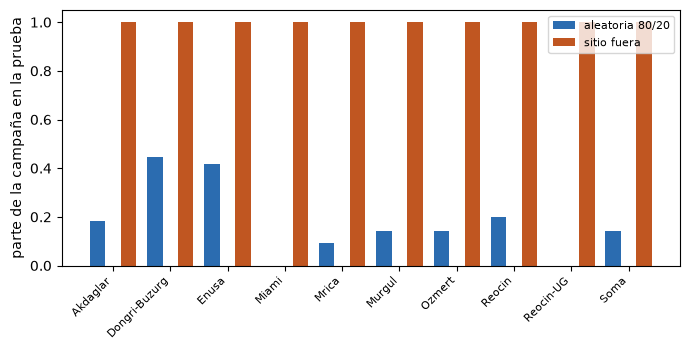

In [6]:
# Parte de cada campaña en el conjunto de prueba: un sorteo aleatorio, y con sitio fuera
sites = sorted({b.site for b in train})
def share(rows, site):
    return sum(1 for b in rows if b.site == site) / sum(1 for b in train if b.site == site)

random_test = [share(split.test, s) for s in sites]
fig, ax = plt.subplots(figsize=(7, 3.6))
position = np.arange(len(sites))
ax.bar(position - 0.27, random_test, 0.27, label="aleatoria 80/20", color="#2b6cb0")
ax.bar(position + 0.27, [1.0] * len(sites), 0.27, label="sitio fuera", color="#c05621")
ax.set_xticks(position, sites, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("parte de la campaña en la prueba")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

**Una división aleatoria filtra, y el motor lo dice.** En el primer sorteo 4 de los 19 tiros de prueba tienen un vector de entradas idéntico en entrenamiento, y en 100 sorteos casi todos llevan al menos un gemelo. Un modelo que memoriza las filas de entrenamiento puntúa bien en una división así sin haber aprendido nada que se transfiera.

**Los gemelos son reales, pocos y locales.** Siete grupos de tiros comparten un vector de entradas, 17 filas en total, dentro de las campañas de Enusa, Mrica y Soma, y los grupos igualan los que versionó la ejecución offline. Colapsarlos elimina los vectores compartidos (diez filas menos) y la división no tiene entonces ningún vector de entradas cruzando el corte, pero no elimina la dependencia entre tiros de una misma campaña.

**Solo dejar una campaña fuera elimina la dependencia.** Los diez pliegues ponen de 6 a 22 tiros en la prueba y los demás sitios en entrenamiento. El motor rechaza una división que pone una campaña a ambos lados, de modo que el protocolo no puede ejecutarse mal por accidente.

**Qué no muestra esto.** Las divisiones dicen qué se deja fuera, no cómo puntúa un modelo en ello. El cuaderno siguiente define los puntajes. Con diez campañas, el puntaje con sitio fuera de cualquier modelo descansa además en diez conjuntos de prueba de tamaños muy distintos, uno de ellos una cuarta parte del corpus.

## Resumen

- Tres divisiones de las mismas filas: aleatoria 80/20 (filtra), sin duplicados (ningún vector de entradas compartido), y una campaña completa fuera por pliegue (ninguna dependencia a través del corte).
- El motor cuenta la fuga en la división aleatoria y rechaza una división inválida de un sitio fuera.
- Siguiente: el cuaderno 02 define el puntaje, el modelo nulo y el intervalo, y aplica el criterio predeclarado del producto.

## Referencias

- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (validación cruzada bajo datos dependientes)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (el protocolo aleatorio 80/20 de los estudios de predictores aprendidos)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/